## Note on changes in this version

This notebook fixes one important issue and adds a few upgrades over the original:

1. **Threshold tuning leakage fix**: the original notebook tuned the Logistic Regression classification
   threshold using the *test set*, then reported metrics on that same test set — which makes the
   reported numbers optimistic (the threshold was picked to look good on the exact data being scored).
   This version tunes thresholds on the **validation set** and only touches the **test set once**, for
   final, honest reporting.
2. **Random Forest threshold tuning** (previously missing) — Random Forest was only ever evaluated at
   the default 0.5 cutoff, while Logistic Regression got a tuned cutoff. This wasn't a fair comparison.
   Both models are now tuned the same way.
3. **Feature importance / interpretability** — added for both models, since a fraud model should be able
   to explain *why* it flagged a transaction.
4. **Light hyperparameter search** for Random Forest using `RandomizedSearchCV`, optimized for PR-AUC
   (better suited to imbalanced data than accuracy).

In [ ]:
import pandas as pd
df = pd.read_csv("credit_card_fraud_2026.csv")
df.head()

,transaction_id,amount_usd,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,hours_since_last_txn,txn_count_last_24h,...,ip_country_mismatch,billing_shipping_mismatch,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,is_ai_generated_scam_attempt,merchant_risk_score,prior_disputes,is_fraud
0,1,42.86,Restaurants,Visa,OTP,Online,Android Phone,False,13.54,2,...,False,False,0.0,0.1,18.0,3.0,False,42.3,0.0,0.0
1,2,4.75,Online Retail,Mastercard,3D Secure,Online,Android Phone,False,0.71,2,...,False,False,0.0,25.8,12.0,4.0,False,28.3,0.0,0.0
2,3,77.18,Groceries,Mastercard,3D Secure,Online,Mac,False,0.35,5,...,False,True,0.0,42.3,5.0,0.0,False,24.7,1.0,0.0
3,4,1.69,Streaming,Visa,No Authentication,POS,Android Phone,False,3.42,6,...,False,False,0.0,28.9,22.0,6.0,False,56.2,1.0,0.0
4,5,261.68,Travel,Visa,3D Secure,In-App,iPhone,False,2.43,2,...,False,False,0.0,3.9,2.0,4.0,False,32.7,0.0,0.0


In [ ]:
print("Shape:", df.shape)

Shape: (7647, 26)


In [ ]:
print("\nData Types")
display(df.dtypes)

print("\nSummary Statistics")
display(df.describe())

print("\nMissing Values")
display(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())


Data Types


transaction_id                    int64
amount_usd                      float64
merchant_category                object
card_type                        object
auth_method                      object
channel                          object
device_type                      object
is_foreign_transaction             bool
hours_since_last_txn            float64
txn_count_last_24h                int64
distance_from_home_km           float64
card_age_months                   int64
customer_age                    float64
account_balance_usd             float64
is_new_merchant                  object
used_vpn                         object
ip_country_mismatch              object
billing_shipping_mismatch        object
cvv_retry_count                 float64
velocity_score                  float64
time_of_day_hour                float64
day_of_week                     float64
is_ai_generated_scam_attempt     object
merchant_risk_score             float64
prior_disputes                  float64



Summary Statistics


,transaction_id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,is_fraud
count,7647.000000,7647.00000,7647.000000,7647.000000,7647.000000,7647.000000,7646.000000,7646.000000,7646.000000,7646.000000,7646.000000,7646.000000,7646.00000,7646.000000,7646.000000
mean,3824.000000,130.32077,8.887704,3.212763,21.990107,46.952400,49.834816,3371.313024,0.172509,19.991721,11.608030,3.001831,37.49673,0.275046,0.017395
std,2207.643087,241.35403,8.735452,1.768547,21.516223,6.711622,18.460756,4449.270761,0.411646,12.383052,6.954042,2.018423,16.90244,0.524430,0.130745
min,1.000000,1.00000,0.010000,0.000000,0.000000,24.000000,18.000000,52.050000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000
25%,1912.500000,25.94000,2.600000,2.000000,6.550000,42.000000,34.000000,1026.452500,0.000000,10.825000,6.000000,1.000000,25.90000,0.000000,0.000000
50%,3824.000000,57.84000,6.220000,3.000000,15.550000,47.000000,50.000000,2020.250000,0.000000,19.100000,12.000000,3.000000,35.70000,0.000000,0.000000
75%,5735.500000,134.60500,12.270000,4.000000,30.690000,51.000000,66.000000,3964.905000,0.000000,27.900000,18.000000,5.000000,47.20000,0.000000,0.000000
max,7647.000000,4309.24000,75.040000,11.000000,215.960000,72.000000,81.000000,88566.000000,3.000000,73.700000,23.000000,6.000000,100.00000,4.000000,1.000000



Missing Values


transaction_id                  0
amount_usd                      0
merchant_category               0
card_type                       0
auth_method                     0
channel                         0
device_type                     0
is_foreign_transaction          0
hours_since_last_txn            0
txn_count_last_24h              0
distance_from_home_km           0
card_age_months                 0
customer_age                    1
account_balance_usd             1
is_new_merchant                 1
used_vpn                        1
ip_country_mismatch             1
billing_shipping_mismatch       1
cvv_retry_count                 1
velocity_score                  1
time_of_day_hour                1
day_of_week                     1
is_ai_generated_scam_attempt    1
merchant_risk_score             1
prior_disputes                  1
is_fraud                        1
dtype: int64


Duplicate Rows: 0


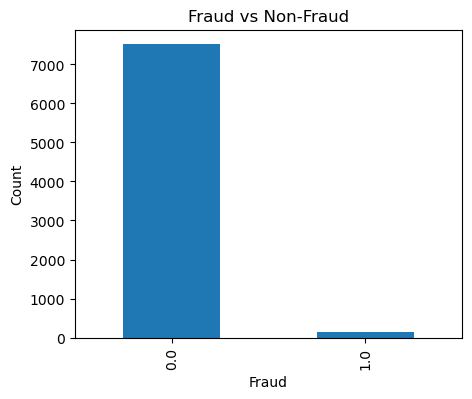

In [ ]:
import matplotlib.pyplot as plt

fraud_counts = df["is_fraud"].value_counts()
plt.figure(figsize=(5,4))
fraud_counts.plot(kind="bar")
plt.title("Fraud vs Non-Fraud")
plt.xlabel("Fraud")
plt.ylabel("Count")
plt.show()

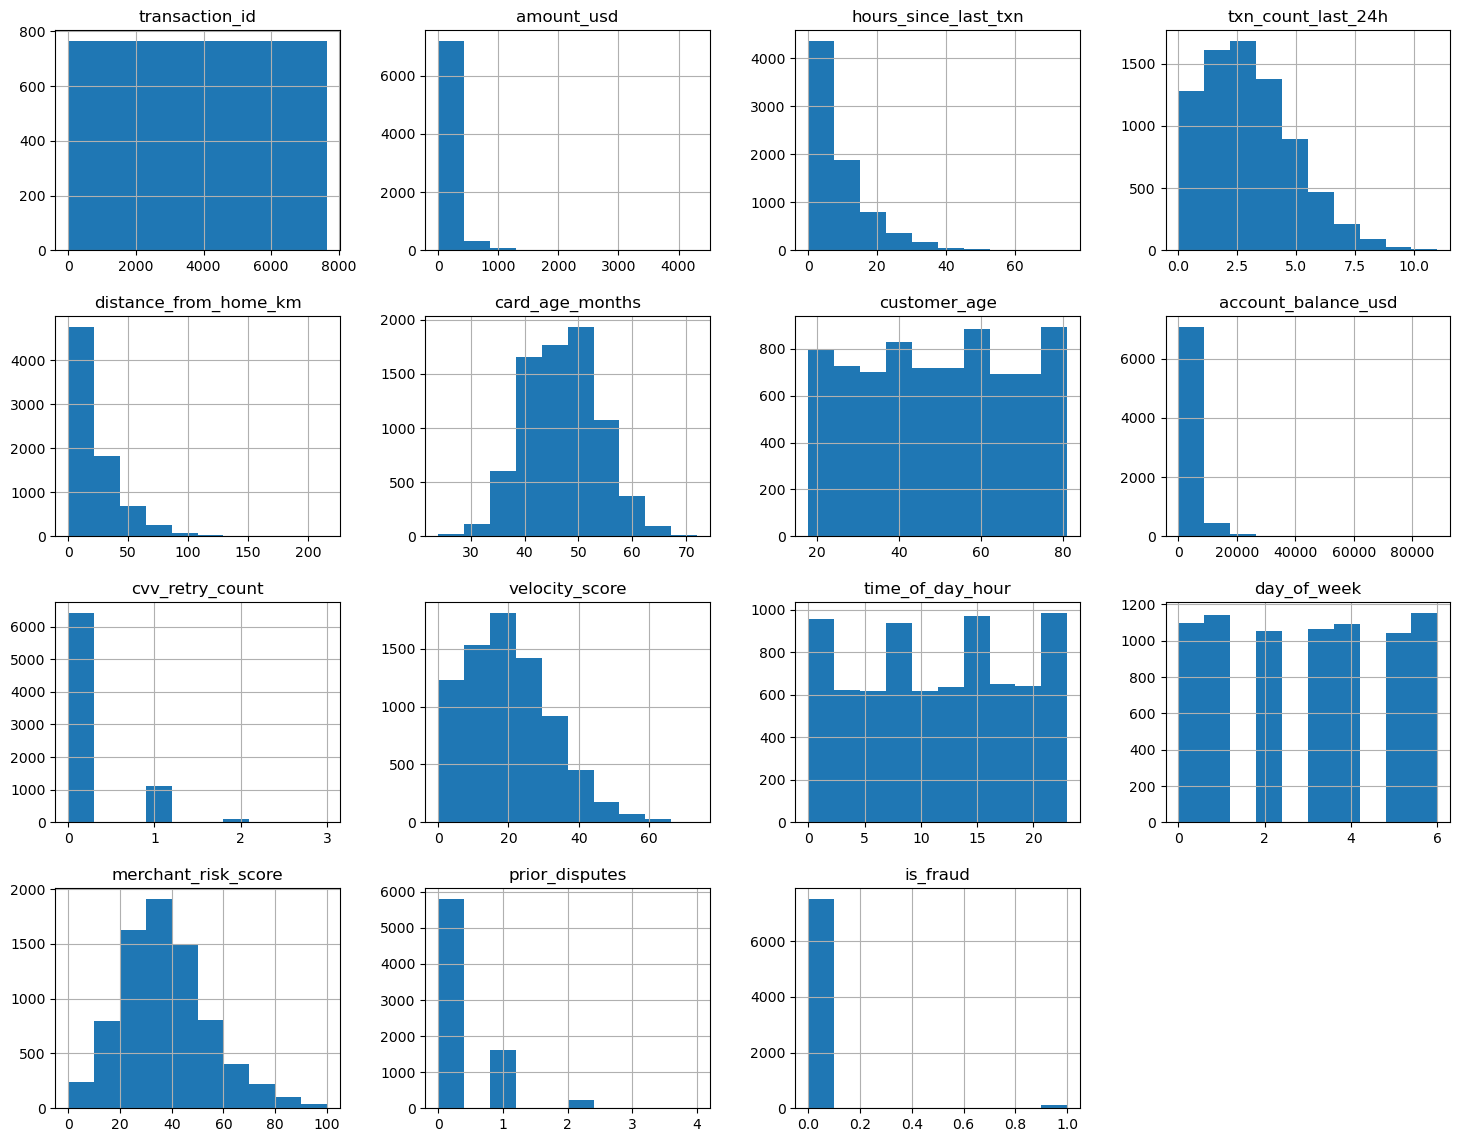

In [ ]:
num_cols = df.select_dtypes(include="number").columns
df[num_cols].hist(figsize=(18,14))
plt.show()

In [ ]:
#The histogram is almost flat  
#Why?
#because transaction IDs are assigned sequentially and each id occurs once and amount_usd Most transactions are small.
#Very few transactions are very large.
#This is called a right-skewed distribution (positive skew).Such skewed variables often benefit from a log transformation.Same for txn_count_last_24h and distance_from_home.Transactions far from a customers usual location may indicate fraud
#the customer_age seems to be the same
#the distribution of account balance is right skewed and so is cvv_retry_count and prior disputes.the is_fraud graph shows us class imbalance
#velocity score is a bit right skewed
#merchant_risk_score shows normal distribution
#the cvv_retry_count is less which shows that most of the times , the cvv has been entered correctly

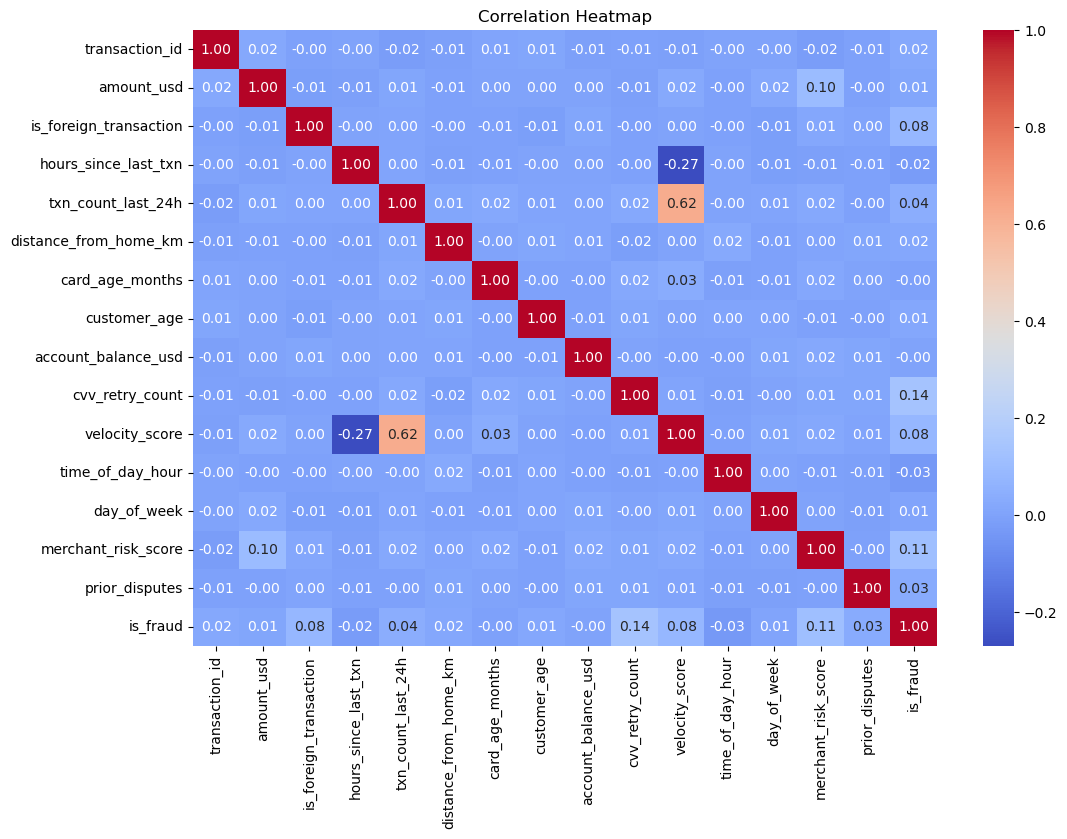

In [ ]:
#annot is used to display the exact numeric values inside the heatmap
#fmap tells us about the number of decimals and cmap is the colour.
#The correlation heatmap is used to see the relationship between numerical variables.if correlation is > 0 , there is a positive relationship between numerical variables and if correlation is < 0 , there is a negative relationship between numerical variables and if correlation is 0 , there is no linear relationship.
#We do this to detect multicollinearity , finding redundant features and understand feature relationships.
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12,8))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")
plt.show()

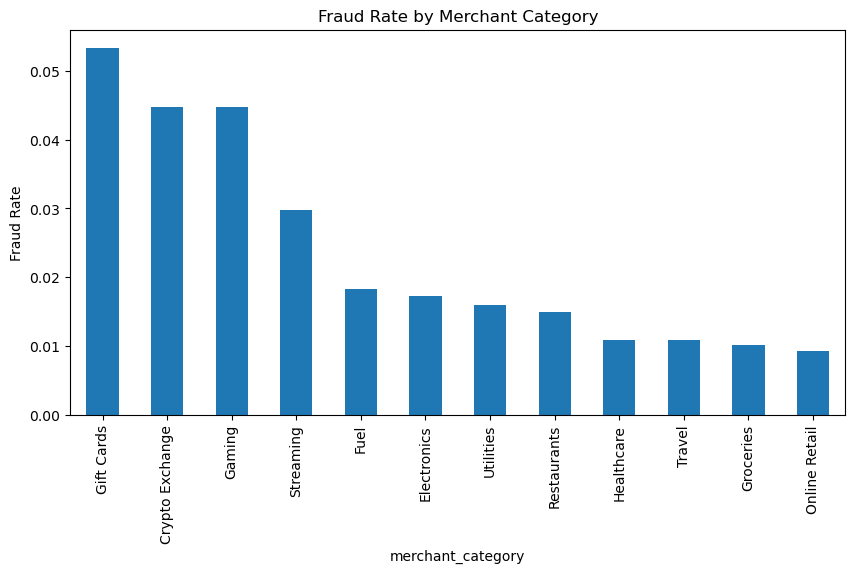

In [ ]:
#We are trying to find the fraud rate based on different merchant category.we can see that gift cards and crypto exchange are the categories where the fraud rate is very high
fraud_rate = (
    df.groupby("merchant_category")["is_fraud"]
      .mean()
      .sort_values(ascending=False)
)

plt.figure(figsize=(10,5))

fraud_rate.plot(kind="bar")

plt.ylabel("Fraud Rate")
plt.title("Fraud Rate by Merchant Category")

plt.show()

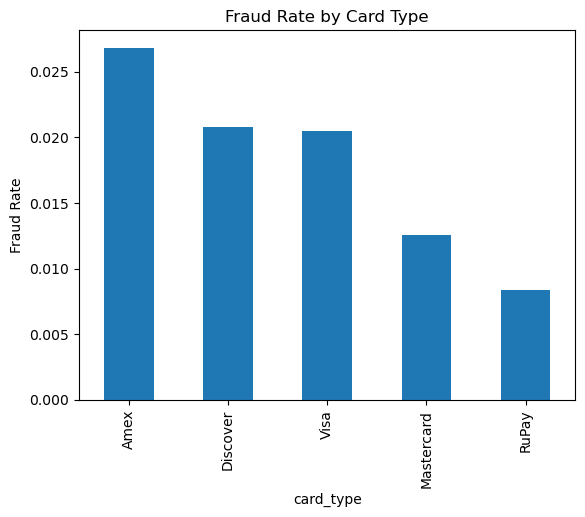

In [ ]:
#Here we are trying to find out which card has a higher fraud rate.here , we can see that amex card gives you a high fraud rate
fraud = (
    df.groupby("card_type")["is_fraud"]
      .mean()
      .sort_values(ascending=False)
)

fraud.plot(kind="bar")

plt.title("Fraud Rate by Card Type")
plt.ylabel("Fraud Rate")

plt.show()

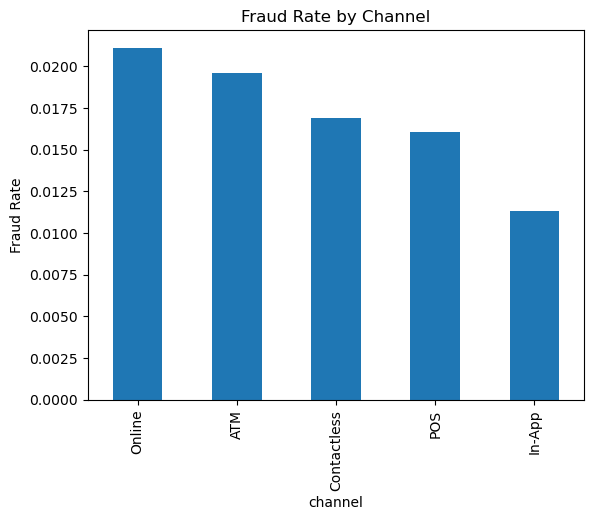

In [ ]:
#Here we are trying to find out by which channel has a higher fraud rate.here , we can see that by online mode , the fraud rate is very high.
fraud_rate = (
    df.groupby("channel")["is_fraud"]
      .mean()
      .sort_values(ascending=False)
)


fraud_rate.plot(kind="bar")

plt.ylabel("Fraud Rate")
plt.title("Fraud Rate by Channel")

plt.show()

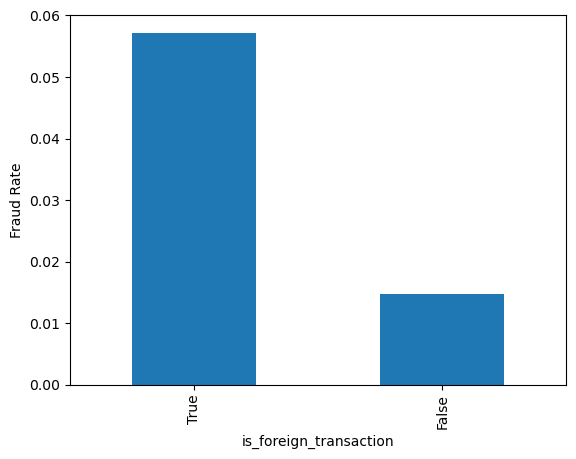

In [ ]:
#We are checking whether the transaction has occured in india or any foreign land because if the transaction has occured in a foreign country , the chances of that transaction being fraud increases because some guy may access your card by taking your card details and then using it in a foreign country
foreign = (
    df.groupby("is_foreign_transaction")["is_fraud"]
      .mean()
      .sort_values(ascending = False)
)

foreign.plot(kind="bar")

plt.ylabel("Fraud Rate")
plt.show()

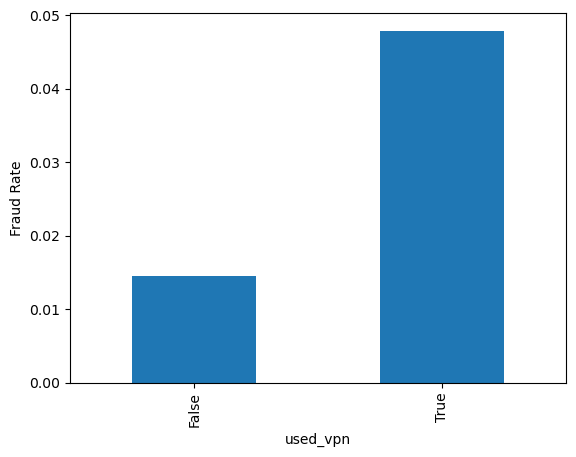

In [ ]:
#We are finding whether fraudsters used vpn or not because Fraudsters often attempt to hide their location through VPNs.
vpn = (
    df.groupby("used_vpn")["is_fraud"]
      .mean()
)

vpn.plot(kind="bar")

plt.ylabel("Fraud Rate")

plt.show()

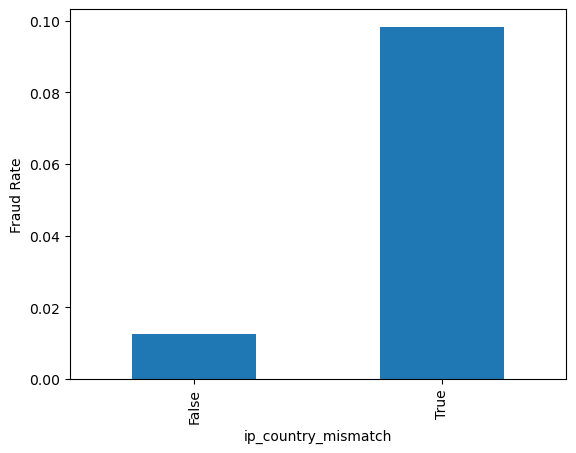

In [ ]:
ip = (
    df.groupby("ip_country_mismatch")["is_fraud"]
      .mean()
)

ip.plot(kind="bar")

plt.ylabel("Fraud Rate")
plt.show()

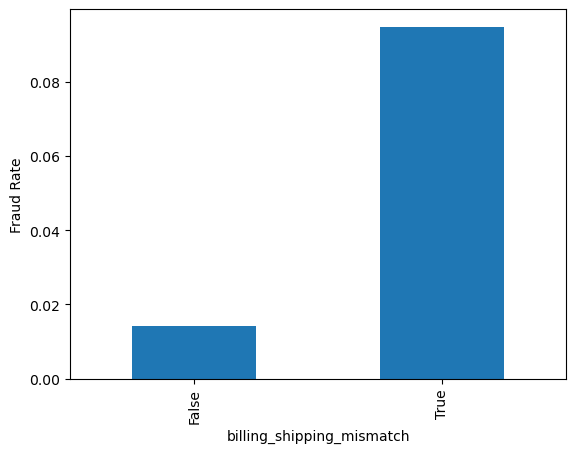

In [ ]:
billing = (
    df.groupby("billing_shipping_mismatch")["is_fraud"]
      .mean()
)

billing.plot(kind="bar")

plt.ylabel("Fraud Rate")
plt.show()

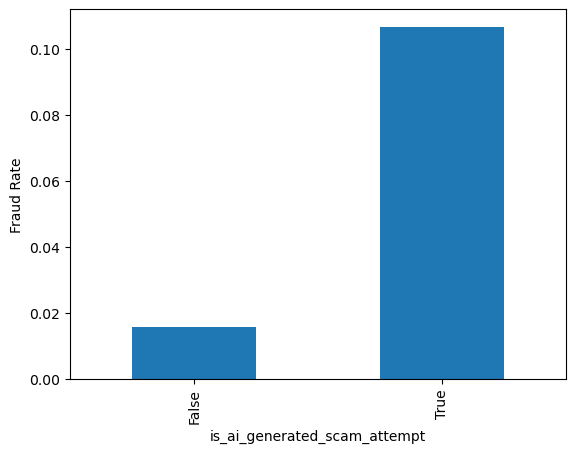

In [ ]:
ai = (
    df.groupby("is_ai_generated_scam_attempt")["is_fraud"]
      .mean()
)

ai.plot(kind="bar")

plt.ylabel("Fraud Rate")
plt.show()

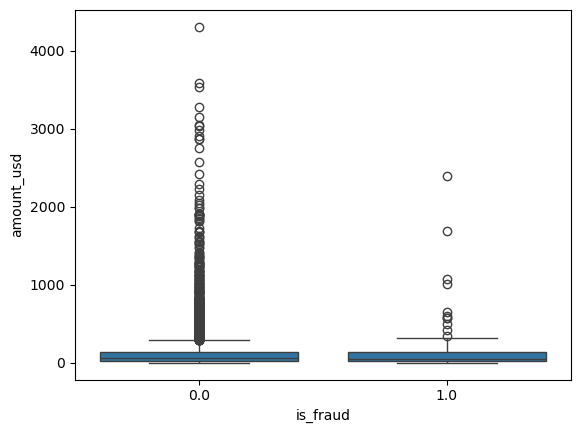

In [ ]:
sns.boxplot(
    data=df,
    x="is_fraud",
    y="amount_usd"
)

plt.show()

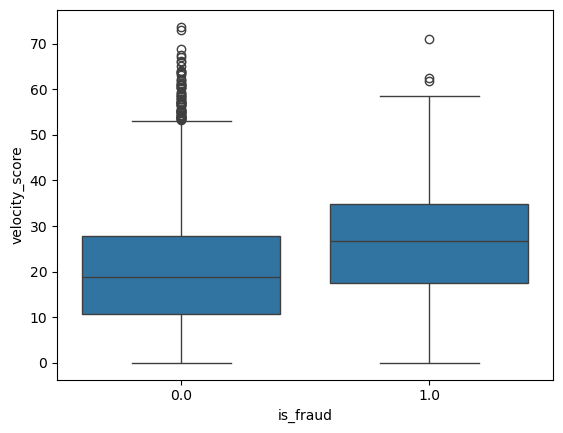

In [ ]:
#A velocity score measures how quickly or unusually frequently a customer is performing transactions within a short period of time.
sns.boxplot(
    data=df,
    x="is_fraud",
    y="velocity_score"
)

plt.show()

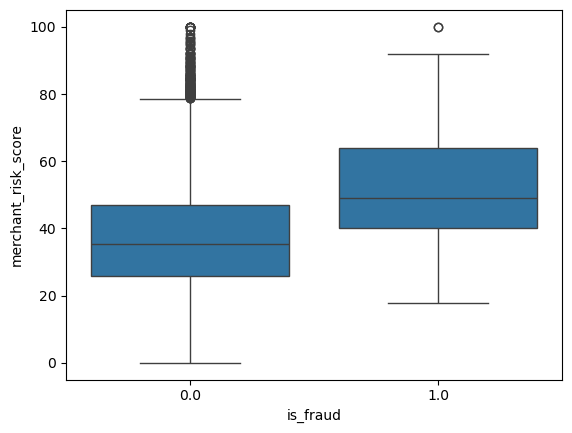

In [ ]:
#A Merchant Risk Score is a numerical score assigned to a merchant (seller/business) that estimates how risky it is to process transactions with that merchant.Usually,a higher score means higher risk.
sns.boxplot(
    data=df,
    x="is_fraud",
    y="merchant_risk_score"
)

plt.show()

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    average_precision_score
)

from imblearn.over_sampling import SMOTE

In [ ]:
df = df.dropna(subset=["is_fraud"])

X = df.drop(columns=["transaction_id", "is_fraud"])
y = df["is_fraud"].astype(int)

In [ ]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.40,
    random_state=42,
    stratify=y
)

In [ ]:
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

In [ ]:
numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "bool"]
).columns.tolist()

In [ ]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

In [ ]:
logistic_model = Pipeline([
    ("preprocessor", preprocessor),

    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

logistic_model.fit(
    X_train,
    y_train
)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['amount_usd',
                                                   'hours_since_last_txn',
                                                   'txn_count_last_24h',
                                                   'distance_from_home_km',
                                                   'card_age_months',
                                                   'customer_age',
                                                   'account_balance_usd',
                                                   'cvv_retry_count',
                                                   'velocity_score',
                                                   'time_of_day_hou...
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['merchant_category',
                                                   'card_type', 'auth_method',
                                                   'channel', 'device_type',
                                                   'is_foreign_transaction',
                                                   'is_new_merchant',
                                                   'used_vpn',
                                                   'ip_country_mismatch',
                                                   'billing_shipping_mismatch',
                                                   'is_ai_generated_scam_attempt'])])),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])

### Logistic Regression — predictions on test *and* validation sets

In [ ]:
lr_pred = logistic_model.predict(X_test)
lr_prob = logistic_model.predict_proba(X_test)[:, 1]

# Probabilities on the VALIDATION set — used ONLY for threshold tuning below.
# The test set stays untouched until the very last step, so our final
# reported numbers are an honest estimate of real-world performance.
lr_val_prob = logistic_model.predict_proba(X_val)[:, 1]

In [ ]:
#here we are testing the results we got with the actual results
lr_accuracy = accuracy_score(
    y_test,
    lr_pred
)

lr_precision = precision_score(
    y_test,
    lr_pred,
    zero_division=0
)

lr_recall = recall_score(
    y_test,
    lr_pred,
    zero_division=0
)

lr_f1 = f1_score(
    y_test,
    lr_pred,
    zero_division=0
)

lr_roc_auc = roc_auc_score(
    y_test,
    lr_prob
)

lr_pr_auc = average_precision_score(
    y_test,
    lr_prob
)

print("Logistic Regression")
print("-----------------------------")
print("Accuracy :", round(lr_accuracy, 4))
print("Precision:", round(lr_precision, 4))
print("Recall   :", round(lr_recall, 4))
print("F1 Score :", round(lr_f1, 4))
print("ROC-AUC  :", round(lr_roc_auc, 4))
print("PR-AUC   :", round(lr_pr_auc, 4))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test,
    lr_pred
))

print("\nClassification Report:")
print(classification_report(
    y_test,
    lr_pred,
    zero_division=0
))

Logistic Regression
-----------------------------
Accuracy : 0.8948
Precision: 0.1278
Recall   : 0.8519
F1 Score : 0.2222
ROC-AUC  : 0.9457
PR-AUC   : 0.5823

Confusion Matrix:
[[1346  157]
 [   4   23]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.90      0.94      1503
           1       0.13      0.85      0.22        27

    accuracy                           0.89      1530
   macro avg       0.56      0.87      0.58      1530
weighted avg       0.98      0.89      0.93      1530



### Threshold tuning — done on the validation set, not the test set

In [ ]:
# FIX: threshold search now runs on (X_val, y_val), not (X_test, y_test).
# Tuning on the test set would let test-set information leak into the choice
# of threshold, inflating the metrics we report afterwards.
thresholds = np.arange(0.05, 0.96, 0.05)

lr_threshold_results = []

for threshold in thresholds:

    pred = (lr_val_prob >= threshold).astype(int)

    precision = precision_score(y_val, pred, zero_division=0)
    recall = recall_score(y_val, pred, zero_division=0)
    f1 = f1_score(y_val, pred, zero_division=0)

    lr_threshold_results.append([threshold, precision, recall, f1])

lr_threshold_df = pd.DataFrame(
    lr_threshold_results,
    columns=["Threshold", "Precision", "Recall", "F1"]
)

display(lr_threshold_df)

,Threshold,Precision,Recall,F1
0,0.05,0.045113,0.923077,0.086022
1,0.10,0.055427,0.923077,0.104575
2,0.15,0.067989,0.923077,0.126649
3,0.20,0.078947,0.923077,0.145455
4,0.25,0.088889,0.923077,0.162162
5,0.30,0.101266,0.923077,0.182510
6,0.35,0.104545,0.884615,0.186992
7,0.40,0.112821,0.846154,0.199095
8,0.45,0.118644,0.807692,0.206897
9,0.50,0.129630,0.807692,0.223404


In [ ]:
best_lr_row = lr_threshold_df.loc[
    lr_threshold_df["F1"].idxmax()
]

best_lr_threshold = best_lr_row["Threshold"]

print("Best threshold :", best_lr_threshold)
print("Precision      :", best_lr_row["Precision"])
print("Recall         :", best_lr_row["Recall"])
print("F1 Score       :", best_lr_row["F1"])

Best threshold : 0.9500000000000001
Precision      : 0.38461538461538464
Recall         : 0.5769230769230769
F1 Score       : 0.46153846153846156


In [ ]:
# The threshold was chosen using validation data above.
# Applying it here to the untouched test set gives an unbiased final read.
lr_tuned_pred = (lr_prob >= best_lr_threshold).astype(int)

print(
    classification_report(
        y_test,
        lr_tuned_pred,
        zero_division=0
    )
)

print("Confusion Matrix:")
print(
    confusion_matrix(
        y_test,
        lr_tuned_pred
    )
)

              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1503
           1       0.52      0.63      0.57        27

    accuracy                           0.98      1530
   macro avg       0.75      0.81      0.78      1530
weighted avg       0.98      0.98      0.98      1530

Confusion Matrix:
[[1487   16]
 [  10   17]]


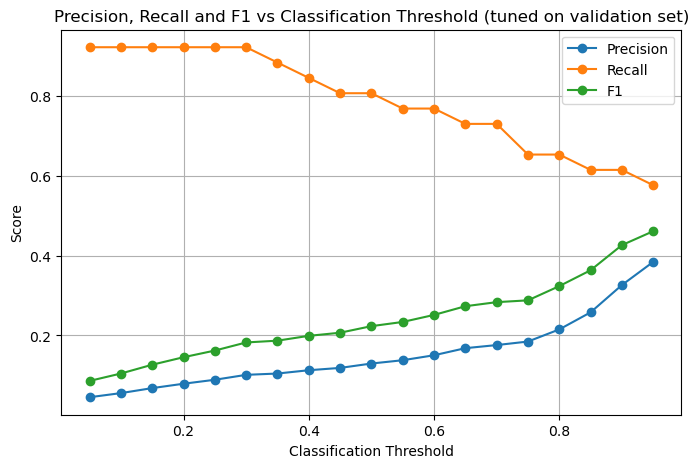

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    lr_threshold_df["Threshold"],
    lr_threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    lr_threshold_df["Threshold"],
    lr_threshold_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    lr_threshold_df["Threshold"],
    lr_threshold_df["F1"],
    marker="o",
    label="F1"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title(
    "Precision, Recall and F1 vs Classification Threshold (tuned on validation set)"
)

plt.legend()
plt.grid()
plt.show()

### Logistic Regression — which features push predictions toward fraud?

In [ ]:
lr_feature_names = logistic_model.named_steps["preprocessor"].get_feature_names_out()
lr_coefs = logistic_model.named_steps["classifier"].coef_[0]

coef_df = pd.DataFrame({
    "feature": lr_feature_names,
    "coefficient": lr_coefs
}).sort_values("coefficient", ascending=False)

print("Top 10 features pushing predictions TOWARD fraud:")
display(coef_df.head(10))

print("\nTop 10 features pushing predictions AWAY FROM fraud:")
display(coef_df.tail(10))

Top 10 features pushing predictions TOWARD fraud:


,feature,coefficient
32,cat__auth_method_No Authentication,1.998510
57,cat__billing_shipping_mismatch_True,1.880196
55,cat__ip_country_mismatch_True,1.715518
8,num__velocity_score,1.544622
26,cat__card_type_Discover,1.460448
59,cat__is_ai_generated_scam_attempt_True,1.408405
53,cat__used_vpn_True,1.359660
11,num__merchant_risk_score,1.266070
22,cat__merchant_category_Streaming,1.231919
49,cat__is_foreign_transaction_True,1.051447



Top 10 features pushing predictions AWAY FROM fraud:


,feature,coefficient
46,cat__device_type_Windows PC,-0.798778
23,cat__merchant_category_Travel,-0.829675
50,cat__is_new_merchant_False,-0.959402
48,cat__is_foreign_transaction_False,-1.052473
28,cat__card_type_RuPay,-1.344876
52,cat__used_vpn_False,-1.360686
58,cat__is_ai_generated_scam_attempt_False,-1.409430
31,cat__auth_method_Biometric,-1.591438
54,cat__ip_country_mismatch_False,-1.716544
56,cat__billing_shipping_mismatch_False,-1.881221


In [ ]:
rf_model = Pipeline([
    ("preprocessor", preprocessor),

    ("classifier", RandomForestClassifier(
        n_estimators=300,
        max_depth=10,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

In [ ]:
rf_model.fit(
    X_train,
    y_train
)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['amount_usd',
                                                   'hours_since_last_txn',
                                                   'txn_count_last_24h',
                                                   'distance_from_home_km',
                                                   'card_age_months',
                                                   'customer_age',
                                                   'account_balance_usd',
                                                   'cvv_retry_count',
                                                   'velocity_score',
                                                   'time_of_day_hou...
                                                  ['merchant_category',
                                                   'card_type', 'auth_method',
                                                   'channel', 'device_type',
                                                   'is_foreign_transaction',
                                                   'is_new_merchant',
                                                   'used_vpn',
                                                   'ip_country_mismatch',
                                                   'billing_shipping_mismatch',
                                                   'is_ai_generated_scam_attempt'])])),
                ('classifier',
                 RandomForestClassifier(class_weight='balanced', max_depth=10,
                                        min_samples_leaf=2, n_estimators=300,
                                        n_jobs=-1, random_state=42))])

In [ ]:
rf_pred = rf_model.predict(X_test)

### Random Forest — predictions on test *and* validation sets

In [ ]:
rf_prob = rf_model.predict_proba(X_test)[:, 1]

# Validation-set probabilities, for threshold tuning only (same reasoning as for LR above).
rf_val_prob = rf_model.predict_proba(X_val)[:, 1]

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

print("Random Forest Results")

print("Accuracy :", accuracy_score(y_test, rf_pred))
print("Precision:", precision_score(y_test, rf_pred, zero_division=0))
print("Recall   :", recall_score(y_test, rf_pred, zero_division=0))
print("F1 Score :", f1_score(y_test, rf_pred, zero_division=0))
print("ROC-AUC  :", roc_auc_score(y_test, rf_prob))
print("PR-AUC   :", average_precision_score(y_test, rf_prob))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_pred))

Random Forest Results
Accuracy : 0.9816993464052287
Precision: 0.0
Recall   : 0.0
F1 Score : 0.0
ROC-AUC  : 0.909341810206747
PR-AUC   : 0.19156333039183393

Confusion Matrix:
[[1502    1]
 [  27    0]]


### Random Forest threshold tuning (previously missing)

The original notebook only ever evaluated Random Forest at the default 0.5 cutoff — which is why it
looked like it "couldn't catch fraud." Its ROC-AUC (~0.91) shows it *can* rank fraud cases as riskier
internally; it just needed its threshold tuned the same way Logistic Regression's was.

In [ ]:
rf_threshold_results = []

for threshold in thresholds:

    pred = (rf_val_prob >= threshold).astype(int)

    precision = precision_score(y_val, pred, zero_division=0)
    recall = recall_score(y_val, pred, zero_division=0)
    f1 = f1_score(y_val, pred, zero_division=0)

    rf_threshold_results.append([threshold, precision, recall, f1])

rf_threshold_df = pd.DataFrame(
    rf_threshold_results,
    columns=["Threshold", "Precision", "Recall", "F1"]
)

display(rf_threshold_df)

,Threshold,Precision,Recall,F1
0,0.05,0.033873,0.884615,0.065248
1,0.10,0.060976,0.769231,0.112994
2,0.15,0.085714,0.576923,0.149254
3,0.20,0.133333,0.461538,0.206897
4,0.25,0.186047,0.307692,0.231884
5,0.30,0.227273,0.192308,0.208333
6,0.35,0.200000,0.076923,0.111111
7,0.40,0.500000,0.076923,0.133333
8,0.45,0.666667,0.076923,0.137931
9,0.50,1.000000,0.038462,0.074074


In [ ]:
best_rf_row = rf_threshold_df.loc[
    rf_threshold_df["F1"].idxmax()
]

best_rf_threshold = best_rf_row["Threshold"]

print("Best RF threshold :", best_rf_threshold)
print("Precision          :", best_rf_row["Precision"])
print("Recall             :", best_rf_row["Recall"])
print("F1 Score           :", best_rf_row["F1"])

Best RF threshold : 0.25
Precision          : 0.18604651162790697
Recall             : 0.3076923076923077
F1 Score           : 0.2318840579710145


In [ ]:
# Apply the validation-chosen threshold to the untouched test set.
rf_tuned_pred = (rf_prob >= best_rf_threshold).astype(int)

print(
    classification_report(
        y_test,
        rf_tuned_pred,
        zero_division=0
    )
)

print("Confusion Matrix:")
print(
    confusion_matrix(
        y_test,
        rf_tuned_pred
    )
)

print("ROC-AUC :", roc_auc_score(y_test, rf_prob))
print("PR-AUC  :", average_precision_score(y_test, rf_prob))

              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1503
           1       0.27      0.30      0.28        27

    accuracy                           0.97      1530
   macro avg       0.63      0.64      0.63      1530
weighted avg       0.97      0.97      0.97      1530

Confusion Matrix:
[[1481   22]
 [  19    8]]
ROC-AUC : 0.909341810206747
PR-AUC  : 0.19156333039183393


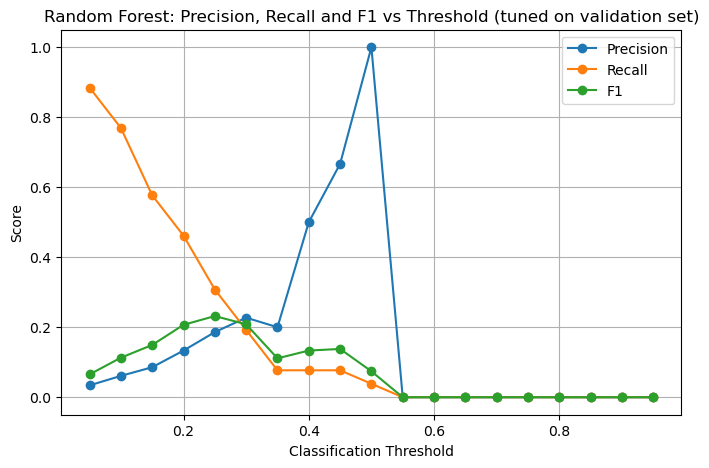

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(rf_threshold_df["Threshold"], rf_threshold_df["Precision"], marker="o", label="Precision")
plt.plot(rf_threshold_df["Threshold"], rf_threshold_df["Recall"], marker="o", label="Recall")
plt.plot(rf_threshold_df["Threshold"], rf_threshold_df["F1"], marker="o", label="F1")

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Random Forest: Precision, Recall and F1 vs Threshold (tuned on validation set)")
plt.legend()
plt.grid()
plt.show()

### Random Forest — which features matter most?

,feature,importance
11,num__merchant_risk_score,0.137509
7,num__cvv_retry_count,0.076154
8,num__velocity_score,0.070225
3,num__distance_from_home_km,0.042851
1,num__hours_since_last_txn,0.037169
0,num__amount_usd,0.036080
54,cat__ip_country_mismatch_False,0.035329
55,cat__ip_country_mismatch_True,0.033984
9,num__time_of_day_hour,0.033967
51,cat__is_new_merchant_True,0.032330


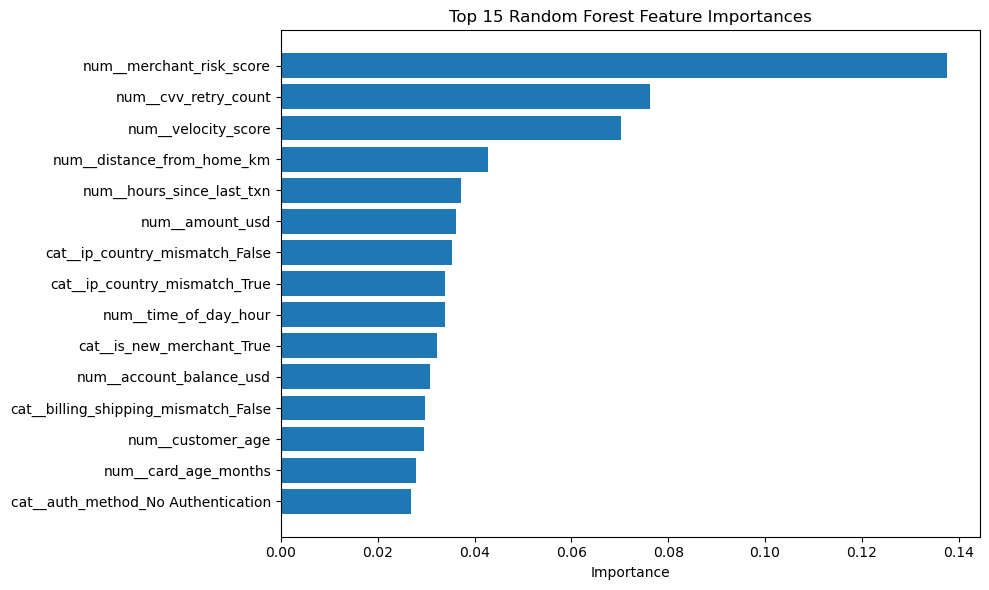

In [ ]:
rf_feature_names = rf_model.named_steps["preprocessor"].get_feature_names_out()
rf_importances = rf_model.named_steps["classifier"].feature_importances_

feat_imp_df = pd.DataFrame({
    "feature": rf_feature_names,
    "importance": rf_importances
}).sort_values("importance", ascending=False)

display(feat_imp_df.head(15))

plt.figure(figsize=(10, 6))
plt.barh(
    feat_imp_df["feature"].head(15)[::-1],
    feat_imp_df["importance"].head(15)[::-1]
)
plt.xlabel("Importance")
plt.title("Top 15 Random Forest Feature Importances")
plt.tight_layout()
plt.show()

### Optional: light hyperparameter search for Random Forest

A small `RandomizedSearchCV`, scored on **PR-AUC** (better suited to imbalanced data than accuracy),
to check whether the original `n_estimators=300, max_depth=10` guess was actually a good choice.
This refits on `X_train` using cross-validation and does not change the `rf_model` used above,
so it won't disturb the results already reported.

In [ ]:
rf_param_grid = {
    "classifier__n_estimators": [200, 300, 500],
    "classifier__max_depth": [6, 10, 15, None],
    "classifier__min_samples_leaf": [1, 2, 4],
    "classifier__max_features": ["sqrt", "log2"]
}

rf_search = RandomizedSearchCV(
    rf_model,
    param_distributions=rf_param_grid,
    n_iter=10,
    scoring="average_precision",   # PR-AUC — better suited to imbalanced data than accuracy
    cv=3,
    random_state=42,
    n_jobs=-1
)

rf_search.fit(X_train, y_train)

print("Best params  :", rf_search.best_params_)
print("Best CV PR-AUC:", rf_search.best_score_)

# Uncomment to adopt the tuned model for the rest of the notebook:
# rf_model = rf_search.best_estimator_

Best params  : {'classifier__n_estimators': 500, 'classifier__min_samples_leaf': 4, 'classifier__max_features': 'sqrt', 'classifier__max_depth': None}
Best CV PR-AUC: 0.1780964823642517


### Random Forest + SMOTE

In [ ]:
X_train_processed = preprocessor.fit_transform(
    X_train
)

In [ ]:
X_test_processed = preprocessor.transform(
    X_test
)

In [ ]:
# Validation set, transformed the same way — for threshold tuning only.
X_val_processed = preprocessor.transform(X_val)

In [ ]:
smote = SMOTE(
    random_state=42
)

In [ ]:
X_train_smote, y_train_smote = smote.fit_resample(
    X_train_processed,
    y_train
)

C:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\ProgramData\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\ProgramData\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^

In [ ]:
rf_smote = RandomForestClassifier(
    n_estimators=300,
    max_depth=10,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

In [ ]:
rf_smote.fit(
    X_train_smote,
    y_train_smote
)

RandomForestClassifier(max_depth=10, min_samples_leaf=2, n_estimators=300,
                       n_jobs=-1, random_state=42)

In [ ]:
rf_smote_pred = rf_smote.predict(X_test_processed)
rf_smote_prob = rf_smote.predict_proba(X_test_processed)[:, 1]

# Validation-set probabilities, for threshold tuning only.
rf_smote_val_prob = rf_smote.predict_proba(X_val_processed)[:, 1]

In [ ]:
rf_smote_threshold_results = []

for threshold in thresholds:

    pred = (rf_smote_val_prob >= threshold).astype(int)

    precision = precision_score(y_val, pred, zero_division=0)
    recall = recall_score(y_val, pred, zero_division=0)
    f1 = f1_score(y_val, pred, zero_division=0)

    rf_smote_threshold_results.append([threshold, precision, recall, f1])

rf_smote_threshold_df = pd.DataFrame(
    rf_smote_threshold_results,
    columns=["Threshold", "Precision", "Recall", "F1"]
)

display(rf_smote_threshold_df)

,Threshold,Precision,Recall,F1
0,0.05,0.049180,0.923077,0.093385
1,0.10,0.070423,0.769231,0.129032
2,0.15,0.093750,0.576923,0.161290
3,0.20,0.121212,0.461538,0.192000
4,0.25,0.166667,0.384615,0.232558
5,0.30,0.200000,0.269231,0.229508
6,0.35,0.238095,0.192308,0.212766
7,0.40,0.400000,0.153846,0.222222
8,0.45,0.428571,0.115385,0.181818
9,0.50,1.000000,0.038462,0.074074


In [ ]:
best_rf_smote_row = rf_smote_threshold_df.loc[
    rf_smote_threshold_df["F1"].idxmax()
]

best_rf_smote_threshold = best_rf_smote_row["Threshold"]

rf_smote_tuned_pred = (rf_smote_prob >= best_rf_smote_threshold).astype(int)

print("Best RF+SMOTE threshold:", best_rf_smote_threshold)
print(classification_report(y_test, rf_smote_tuned_pred, zero_division=0))
print("Confusion Matrix:")
print(confusion_matrix(y_test, rf_smote_tuned_pred))

Best RF+SMOTE threshold: 0.25
              precision    recall  f1-score   support

           0       0.99      0.97      0.98      1503
           1       0.24      0.44      0.31        27

    accuracy                           0.97      1530
   macro avg       0.61      0.71      0.65      1530
weighted avg       0.98      0.97      0.97      1530

Confusion Matrix:
[[1465   38]
 [  15   12]]


In [ ]:
risk_score = (
    rf_smote_prob * 100
).round(2)

In [ ]:
pd.cut(
    risk_score,
    bins=[-1, 30, 70, 100],
    labels=[
        "Low Risk",
        "Medium Risk",
        "High Risk"
    ]
)

['Low Risk', 'Low Risk', 'Low Risk', 'Low Risk', 'Low Risk', ..., 'Low Risk', 'Low Risk', 'Low Risk', 'Low Risk', 'Low Risk']
Length: 1530
Categories (3, object): ['Low Risk' < 'Medium Risk' < 'High Risk']

In [ ]:
print("Random Forest + SMOTE Results")

print("Accuracy :", accuracy_score(y_test, rf_smote_pred))
print("Precision:", precision_score(y_test, rf_smote_pred, zero_division=0))
print("Recall   :", recall_score(y_test, rf_smote_pred, zero_division=0))
print("F1 Score :", f1_score(y_test, rf_smote_pred, zero_division=0))
print("ROC-AUC  :", roc_auc_score(y_test, rf_smote_prob))
print("PR-AUC   :", average_precision_score(y_test, rf_smote_prob))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_smote_pred))

Random Forest + SMOTE Results
Accuracy : 0.9823529411764705
Precision: 0.5
Recall   : 0.037037037037037035
F1 Score : 0.06896551724137931
ROC-AUC  : 0.9201596806387227
PR-AUC   : 0.2788583536981816

Confusion Matrix:
[[1502    1]
 [  26    1]]
